## Импорт библиотек

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression, SGDRegressor
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

In [2]:
# Загрузка датасета
df = pd.read_csv("Life Expectancy Data.csv")

df = df.dropna()
# Убираем строки с пустыми значениями

df = df.drop(['infant_deaths', 'under-five_deaths', 'thinness_1-19_years', 'thinness_5-9_years', 'Total_expenditure', 'Year', 'Country'], axis=1)

df = pd.get_dummies(df, drop_first=True)

X = df.drop("Life_expectancy", axis=1)
y = df["Life_expectancy"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(X_train.shape)
# print(df.isna().any())

(1319, 14)


Обучающая выборка имеет 1319 строк и 13 атрибутов

In [3]:
median_class = y_train.median()
y_train_class = (y_train>median_class).astype(int)
y_test_class = (y_test>median_class).astype(int)
clf = LogisticRegression(max_iter=1000, random_state=42)
clf.fit(X_train, y_train_class)
sample_probs = clf.predict_proba(X_test[:5])[:, 1]
sample_preds = clf.predict(X_test[:5])

results_class = pd.DataFrame(
    {
        "Вероятность (Сигмоида)":sample_probs,
        "Класс (Порог 0.5)":sample_preds,
        "Факт (Реальность)":y_test_class.iloc[:5].values,
    }
)
display(results_class.round(3))
print(f"Accuracy: {accuracy_score(y_test_class, clf.predict(X_test)):.4f}")

,Вероятность (Сигмоида),Класс (Порог 0.5),Факт (Реальность)
0,0.490,0,0
1,0.872,1,1
2,1.000,1,1
3,0.000,0,0
4,0.000,0,0


Accuracy: 0.8697


По первым пяти признакам видно, что Класс и Факт предсказывают друг друга верно, но Вероятность у одного из элементов равна единице. Значит модель завышает данные.

## Регрессия: MHK и SGD

In [4]:
start_ols = time.time()
ols = LinearRegression()
ols.fit(X_train, y_train)
time_ols = time.time()-start_ols
pred_ols = ols.predict(X_test)

start_sgd = time.time()
sgd = SGDRegressor(
    max_iter=1000,
    tol=1e-3,
    eta0=0.01,
    learning_rate="adaptive",
    random_state=42
)
sgd.fit(X_train, y_train)
time_sgd = time.time() - start_sgd
pred_sgd = sgd.predict(X_test)

rmse_ols = np.sqrt(mean_squared_error(y_test, pred_ols))
r2_ols = r2_score(y_test, pred_ols)
rmse_sgd = np.sqrt(mean_squared_error(y_test, pred_sgd))
r2_sgd = r2_score(y_test, pred_ols)

print(f'MHK (Аналитический): RMSE = ${rmse_ols:,.2f} | R2 = {r2_ols:,.2f} | Время = {time_ols:,.5f} сек')
print(f'SGD (Итеративный): RMSE = ${rmse_sgd:,.2f} | R2 = {r2_sgd:,.2f} | Время = {time_sgd:,.5f} сек')

MHK (Аналитический): RMSE = $3.72 | R2 = 0.80 | Время = 0.00450 сек
SGD (Итеративный): RMSE = $3.72 | R2 = 0.80 | Время = 0.01670 сек


MHK и SGD показывают одинаковые данные, но МНК работает быстрее

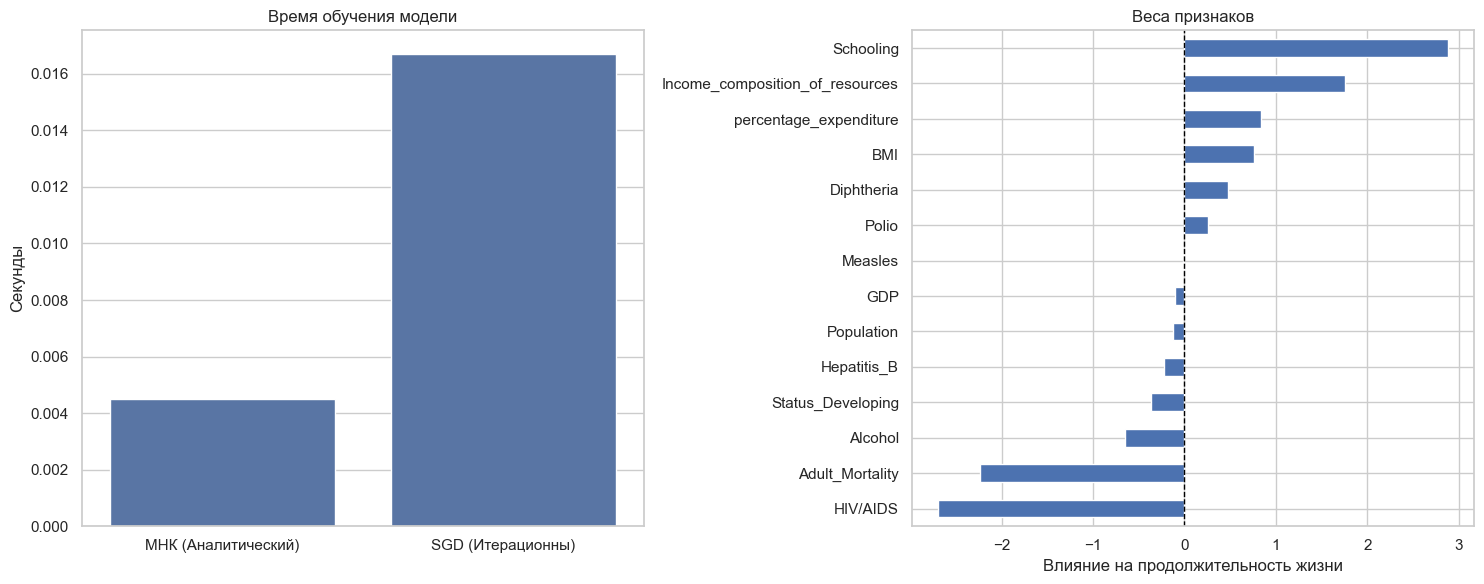

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1 Сравнение времени выполнения
sns.barplot(
    x=['МНК (Аналитический)', 'SGD (Итерационны)'],
    y=[time_ols, time_sgd],
    ax=axes[0],
)
axes[0].set_title('Время обучения модели')
axes[0].set_ylabel('Секунды')

weights = pd.Series(ols.coef_, index=X.columns).sort_values()
weights.plot(kind='barh', ax=axes[1])
axes[1].set_title('Веса признаков')
axes[1].set_xlabel('Влияние на продолжительность жизни')
axes[1].axvline(0, color='black', linestyle='--', lw=1)

plt.tight_layout()
plt.show()


Из схем видно, что образование даёт наибольший прирост к продолжительности жизни, уже после идут заработок, траты на здравоохранение и ИМТ. Но также модель в положительные признаки записала Дифтирию и Полиомелит. А в отрицательные записал ВВП.